# Track retrieval and candidate listeners

Retrieve similar training songs for each new track in the [fixed validation split](02_data_splitting.ipynb), then rank their listeners. All tables and figures use the same [completed experiment](../validation/retrieval_snapshot.json). See the [retrieval implementation](../scripts/retrieval.py) and [full experiment instructions](../README.md#validate-the-candidate-pool-and-benchmark-retrieval).

In [1]:
from hashlib import sha256
import json
from pathlib import Path
import sys

from IPython.display import Markdown, display
%matplotlib inline

root = Path.cwd()
if not (root / "pyproject.toml").is_file():
    root = root.parent
sys.path.insert(0, str(root))
from scripts.plot_lsh_s_curve import scaling_figure, s_curve_figure

data = (root / "validation/retrieval_snapshot.json").read_bytes()
if sha256(data).hexdigest() != "da429d424a21cdf0296e16b7c654e761824d9449fe5dd150c15d143c749b1ad0":
    raise ValueError("The validation snapshot differs from the published run.")
result = json.loads(data)
run = result["run"]

def table(headers, rows):
    lines = [headers, ["---"] * len(headers), *rows]
    display(Markdown("\n".join(" | ".join(map(str, row)) for row in lines)))

## 1. Training index

Training ends before 2018-01-01. An old song needs original tags and at least one eligible training listener. The frequency cap uses this cohort before empty tag sets are removed.

In [2]:
table(["Cohort", "Count"], [
    ["Eligible training listeners", f'{result["split"]["counts"]["eligible_users"]:,}'],
    ["Training songs before filtering", f'{run["training_tracks"]:,}'],
    ["Training songs emptied by filtering", run["emptied_training_tracks"]],
    ["Training songs indexed", f'{run["indexed_training_tracks"]:,}'],
    ["Validation songs", f'{run["queries"]:,}'],
])

Cohort | Count
--- | ---
Eligible training listeners | 105,578
Training songs before filtering | 42,440
Training songs emptied by filtering | 107
Training songs indexed | 42,333
Validation songs | 1,274

## 2. Tag selection

Fit both filters on training songs. The first table applies only the weight threshold. The second compares listener Recall@100 from exact retrieval across all 15 trials, with NDCG@100 breaking ties.

In [3]:
table(["Minimum weight", "P10 tags", "Median tags", "P90 tags", "Empty", "Empty share"], [
    [s["min_weight"], int(s["p10"]), int(s["median"]), int(s["p90"]),
     s["empty_tracks"], f'{s["empty_fraction"]:.3%}']
    for s in result["tag_statistics"]
])

Minimum weight | P10 tags | Median tags | P90 tags | Empty | Empty share
--- | --- | --- | --- | --- | ---
0 | 4 | 29 | 97 | 0 | 0.000%
10 | 4 | 10 | 29 | 0 | 0.000%
20 | 3 | 6 | 16 | 3 | 0.007%
34 | 2 | 4 | 10 | 55 | 0.130%
50 | 1 | 3 | 7 | 241 | 0.568%

In [4]:
recall = {(t["min_weight"], t["max_tag_fraction"]): t["recall_at_100"] for t in result["tag_trials"]}
weights = [s["min_weight"] for s in result["tag_statistics"]]

table(["Minimum weight", "No cap", "50% cap", "25% cap"], [
    [w, *[f"{recall[w, cap]:.3%}" for cap in (None, .50, .25)]] for w in weights
])
print(f'Selected weight ≥ {run["min_weight"]}, cap {run["max_tag_fraction"]:.0%}.')
print("Removed tags:", ", ".join(run["excluded_tags"]))

Minimum weight | No cap | 50% cap | 25% cap
--- | --- | --- | ---
0 | 15.486% | 15.486% | 15.602%
10 | 13.314% | 13.314% | 13.466%
20 | 12.391% | 12.391% | 12.639%
34 | 11.875% | 11.875% | 11.951%
50 | 11.516% | 11.516% | 11.516%

Selected weight ≥ 0, cap 25%.
Removed tags: alternative, pop, rock


## 3. Positive neighbors

Exact search keeps up to 50 songs with positive Jaccard similarity, breaking ties by track ID. Neighbor Recall@50 is the fraction of that list recovered, averaged over queries with at least one positive neighbor. The S curves use the pooled positive similarities.

87 queries have fewer than 50 positive neighbors.
21 have none. Neighbor recall covers 1,253 queries.


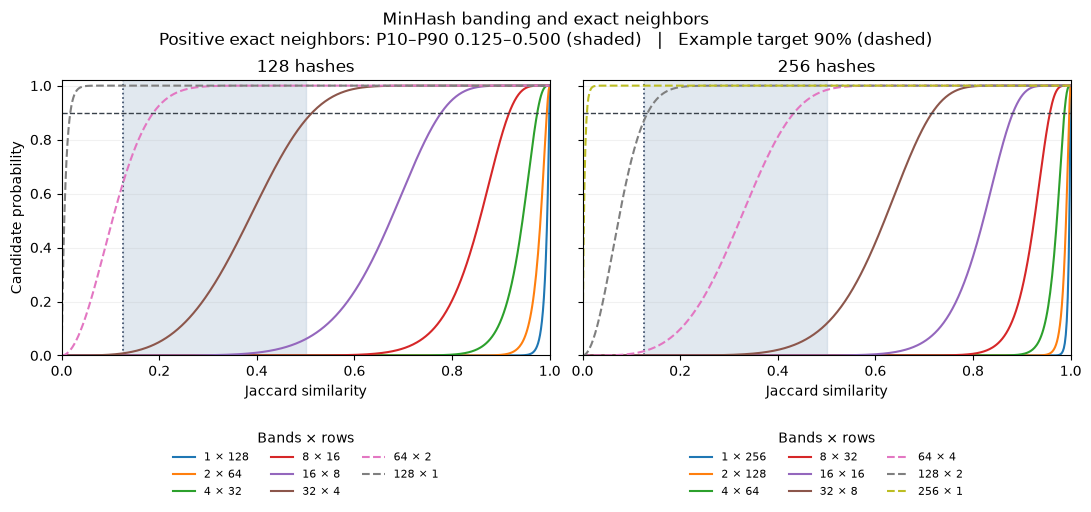

In [5]:
quantiles = run["neighbor_jaccard"]["train_100"]
print(f'{run["short_positive_queries"]} queries have fewer than 50 positive neighbors.')
print(f'{run["no_positive_queries"]} have none. Neighbor recall covers {run["queries"] - run["no_positive_queries"]:,} queries.')
s_curve_figure(quantiles["p10"], quantiles["p90"], run["target_probability"]);

## 4. Retrieval benchmark

Test 128 and 256 hashes on the same validation queries. Select the fastest LSH configuration meeting both provisional 90% targets on the full training index: theoretical candidate probability at positive Jaccard P10 and measured neighbor recall. The table covers every configuration on that index.

In [6]:
bench = result["benchmark"]
def configuration(row):
    return "Sparse exact" if row["method"] == "sparse_exact" else f'{row["bands"]} × {row["rows"]}'

table(["Bands × rows", "Build (s)", "p50 (ms)", "p95 (ms)", "Peak (MiB)",
       "Mean candidates", "P(match) at P10", "Neighbor R@50"], [
    [configuration(r), f'{float(r["build_seconds"]):.2f}', f'{float(r["query_p50_ms"]):.3f}',
     f'{float(r["query_p95_ms"]):.3f}', f'{float(r["peak_rss_mib"]):.0f}',
     f'{float(r["mean_candidates"]):,.1f}',
     f'{float(r["candidate_probability_at_p10"]):.2%}' if r["bands"] else "—",
     f'{float(r["neighbor_recall"]):.2%}']
    for r in bench if r["scope"] == "train_100"
])
print("Selected LSH:", configuration(run["fastest_meeting_targets"]))

Bands × rows | Build (s) | p50 (ms) | p95 (ms) | Peak (MiB) | Mean candidates | P(match) at P10 | Neighbor R@50
--- | --- | --- | --- | --- | --- | --- | ---
Sparse exact | 0.62 | 0.533 | 0.982 | 393 | 42,333.0 | — | 100.00%
1 × 128 | 2.24 | 0.017 | 0.042 | 681 | 2.3 | 0.00% | 4.68%
2 × 64 | 2.34 | 0.021 | 0.059 | 640 | 2.3 | 0.00% | 4.68%
4 × 32 | 2.29 | 0.024 | 0.051 | 681 | 2.3 | 0.00% | 4.68%
8 × 16 | 2.25 | 0.035 | 0.074 | 686 | 2.4 | 0.00% | 4.91%
16 × 8 | 2.28 | 0.062 | 0.122 | 682 | 3.7 | 0.00% | 6.94%
32 × 4 | 2.43 | 0.119 | 0.243 | 690 | 26.8 | 0.78% | 27.91%
64 × 2 | 2.76 | 0.730 | 2.506 | 705 | 747.9 | 63.50% | 86.96%
128 × 1 | 3.06 | 5.313 | 21.947 | 702 | 6,550.9 | 100.00% | 99.55%
1 × 256 | 3.49 | 0.019 | 0.049 | 922 | 2.3 | 0.00% | 4.68%
2 × 128 | 3.32 | 0.023 | 0.062 | 963 | 2.3 | 0.00% | 4.68%
4 × 64 | 3.33 | 0.025 | 0.054 | 880 | 2.3 | 0.00% | 4.68%
8 × 32 | 3.32 | 0.035 | 0.065 | 922 | 2.3 | 0.00% | 4.70%
16 × 16 | 3.34 | 0.057 | 0.095 | 928 | 2.4 | 0.00% | 4.97%
32 × 8 | 3.47 | 0.100 | 0.167 | 927 | 4.8 | 0.00% | 8.46%
64 × 4 | 4.06 | 0.219 | 0.373 | 940 | 39.6 | 1.55% | 37.37%
128 × 2 | 4.61 | 1.296 | 4.137 | 963 | 1,205.3 | 86.68% | 93.25%
256 × 1 | 5.12 | 6.501 | 23.748 | 963 | 7,103.2 | 100.00% | 99.95%

Selected LSH: 128 × 1


The first three sizes are nested training subsets. The last starts from all 88,092 originally tagged songs, drops empty sets and excludes self-matches. It measures retrieval only. At all four measured sizes, sparse exact search has a lower median query time than every LSH configuration meeting both targets.

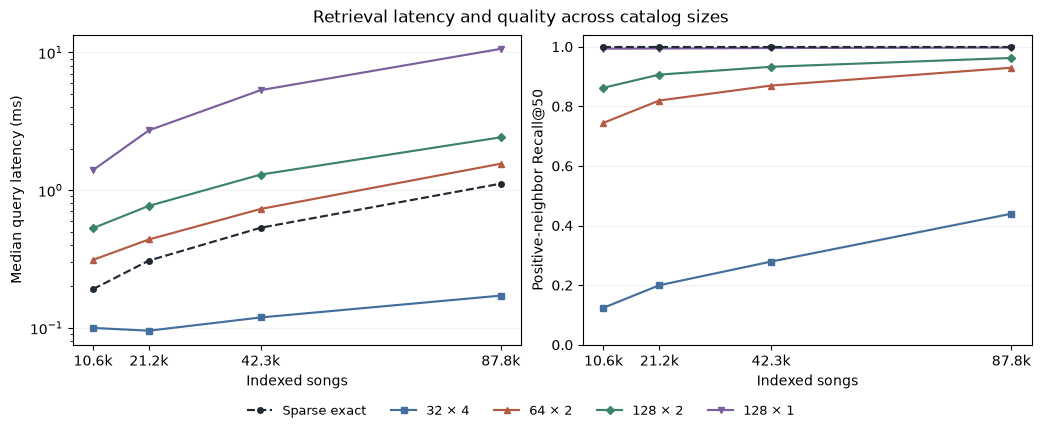

In [7]:
scaling_figure(bench, run["top_n"]);

## 5. Listener rankings

A listener earns Jaccard similarity × log(1 + plays) for each neighbor they played at least twice in training. Unused eligible listeners fill short lists in descending order of total training plays. B's evaluator scores 1,000 distinct users per song against listeners observed in its first 30 days.

In [8]:
def method_name(name):
    return {"sparse_exact": "Sparse exact", "popularity": "Training activity"}.get(
        name, name.replace("lsh_", "LSH ").replace("x", " × "))

metrics = ["recall_at_100", "recall_at_500", "recall_at_1000",
           "ndcg_at_100", "ndcg_at_500", "ndcg_at_1000"]
table(["Method", "R@100", "R@500", "R@1000", "NDCG@100", "NDCG@500", "NDCG@1000"], [
    [method_name(r["method"]), *[f"{r[m]:.3%}" for m in metrics]] for r in result["metrics"]
])

Method | R@100 | R@500 | R@1000 | NDCG@100 | NDCG@500 | NDCG@1000
--- | --- | --- | --- | --- | --- | ---
Training activity | 0.965% | 7.402% | 13.417% | 1.107% | 3.697% | 5.971%
Sparse exact | 15.602% | 32.562% | 42.145% | 16.143% | 21.738% | 25.535%
LSH 32 × 4 | 10.674% | 22.659% | 30.218% | 10.304% | 14.677% | 17.701%
LSH 128 × 1 | 15.602% | 32.556% | 42.116% | 16.143% | 21.736% | 25.527%

## 6. Why songs need fallback

Classify in order: **a** original tags removed, **b** fewer than 50 positive neighbors, **c** 50 neighbors but fewer than 1,000 distinct candidate listeners, **d** both counts sufficient. A song in **b** can still have 1,000 candidates. Mean fill and final listener Recall@1000 use all songs in each group. A dash marks an empty group.

In [9]:
groups = result["fallback_groups"]
names = {"a_emptied": "a · Tags emptied", "b_few_neighbors": "b · Few neighbors",
         "c_few_candidates": "c · Few listeners", "d_ok": "d · Sufficient"}
table(["Method", "Group", "Songs", "Need fill", "Mean slots filled", "Listener R@1000"], [
    [method_name(g["method"]), names[g["category"]], g["tracks"], g["filled_tracks"],
     f'{g["mean_fill"]:,.1f}' if g["tracks"] else '—',
     f'{g["recall_at_1000"]:.2%}' if g["scored_tracks"] else '—'] for g in groups
])

Method | Group | Songs | Need fill | Mean slots filled | Listener R@1000
--- | --- | --- | --- | --- | ---
Sparse exact | a · Tags emptied | 10 | 10 | 1,000.0 | 25.27%
Sparse exact | b · Few neighbors | 77 | 35 | 379.7 | 30.14%
Sparse exact | c · Few listeners | 31 | 31 | 383.7 | 80.08%
Sparse exact | d · Sufficient | 1156 | 0 | 0.0 | 42.07%
LSH 32 × 4 | a · Tags emptied | 10 | 10 | 1,000.0 | 25.27%
LSH 32 × 4 | b · Few neighbors | 1052 | 653 | 479.5 | 27.92%
LSH 32 × 4 | c · Few listeners | 0 | 0 | — | —
LSH 32 × 4 | d · Sufficient | 212 | 0 | 0.0 | 41.85%
LSH 128 × 1 | a · Tags emptied | 10 | 10 | 1,000.0 | 25.27%
LSH 128 × 1 | b · Few neighbors | 78 | 36 | 381.8 | 29.37%
LSH 128 × 1 | c · Few listeners | 31 | 31 | 383.7 | 80.08%
LSH 128 × 1 | d · Sufficient | 1155 | 0 | 0.0 | 42.10%

Of the 76 exact-search songs that need fill, 10 lose all tags, 35 have too few positive neighbors and 31 have 50 neighbors but too few listeners. Emptied queries represent 0.78% of validation songs, so they keep the activity fallback.

With LSH 32 × 4, 653 of 663 songs needing fill have fewer than 50 positive matches despite retaining tags. Exact search finds 50 for 576 of those songs.